# How Bad Can Things Get? Extreme-Value VaR for an S&P 500 Position
## Empirical, EWMA-normal, GEV block-maxima and GP peaks-over-threshold VaR for $0.99\le\alpha\le0.9999$

Each day a \$1,000,000 position in the S&P 500 index is held, and its one-day loss is
estimated with the linearized operator $L^{\mathrm{lin}}=-VX$, where $X$ is the daily
log return. Using $N+1=2556$ daily closes from 11/01/2011 to 12/29/2021
($N=2555$ log returns), this notebook estimates $\mathrm{VaR}_\alpha$ as a function of
$\alpha$ by four methods — the empirical distribution, a normal model with EWMA mean and
variance, a GEV fit to block maxima (blocks of $n=73$ and $n=35$ days), and a generalised
Pareto fit to the losses above $u=\widehat{\mathrm{VaR}}_{0.95}$ — plots
$\alpha\mapsto\mathrm{VaR}_\alpha$ on $[0.99,0.9999]$ and compares the estimates at
$\alpha=0.9999$.

**The four VaR estimates.** With losses $\ell_j=-Vx_j$ sorted as $\ell_{(1)}\le\dots\le\ell_{(N)}$:

1. empirical: $\widehat{\mathrm{VaR}}_\alpha=\ell_{(\lceil N\alpha\rceil)}$;
2. normal, $X_{t+\Delta}\mid\mathcal F_t\sim N(\mu_{t+\Delta},\sigma^2_{t+\Delta})$:
   $\mathrm{VaR}_\alpha=-V\mu_{t+\Delta}+V\sigma_{t+\Delta}\Phi^{-1}(\alpha)$;
3. block maxima: if the maximum $M_n$ of $n$ daily losses has cdf
   $F^n\approx H_{\xi,\mu,\sigma}$ (GEV), then $F(x)\approx H_{\xi,\mu,\sigma}(x)^{1/n}$ and
   $$\mathrm{VaR}_\alpha=H_{\xi,\mu,\sigma}^{-1}(\alpha^n)=\mu-\frac{\sigma}{\xi}\Bigl[1-\bigl(-n\log\alpha\bigr)^{-\xi}\Bigr],
   \qquad H_{\xi,\mu,\sigma}(x)=\exp\Bigl\{-\Bigl(1+\xi\,\tfrac{x-\mu}{\sigma}\Bigr)^{-1/\xi}\Bigr\};$$
4. peaks over threshold: if the excess $L-u\mid L>u$ is $\mathrm{GP}(\xi,\beta)$, then for
   $x\ge u$, $1-F(x)=(1-F(u))\bigl(1+\xi\tfrac{x-u}{\beta}\bigr)^{-1/\xi}$ and
   $$\mathrm{VaR}_\alpha=u+\frac{\beta}{\xi}\Bigl[\Bigl(\frac{1-F(u)}{1-\alpha}\Bigr)^{\xi}-1\Bigr],\qquad F(u)=0.95 .$$

These are the formulas of lecture 7 (slides 21–22 and 31).

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import optimize
from scipy.stats import norm, genextreme, genpareto
import matplotlib
import matplotlib.pyplot as plt

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.1.3
pandas      2.2.3
scipy       1.15.3
matplotlib  3.10.0


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| — | index | S&P 500 (`^GSPC`), daily closes |
| $N+1$ | number of closes, from 11/01/2011 | 2556 (to 12/29/2021) |
| $V$ | position held each day | \$1,000,000 |
| $\alpha$ | VaR levels | $0.99+0.000099k$, $k=0,\dots,100$ |
| $t$ | date of the EWMA forecast | 11/01/2021 |
| $\lambda,\ \theta$ | EWMA decay, mean and variance | 0.97, 0.97 |
| — | EWMA initialisation | sample mean and variance of the first 100 returns |
| $(n,m)$ | block size and number of blocks | (73, 35) and (35, 73) |
| $u$ | POT threshold | empirical $\widehat{\mathrm{VaR}}_{0.95}$ from method 1 |
| $F(u)$ | used in the POT formula | 0.95 |

In [2]:
FIRST_DAY  = "2011-11-01"
SHEET_LAST = "2021-12-29"
N_PRICES   = 2556                 # N + 1 closes  ->  N = 2555 log returns
V_PORT     = 1_000_000.0
T_EWMA     = "2021-11-01"         # the EWMA forecast is made at the close of this day
LAM = THETA = 0.97
N_INIT     = 100                  # EWMA initialisation window (returns)
BLOCKS     = [(73, 35), (35, 73)] # (block size n, number of blocks m)
ALPHA_U    = 0.95                 # POT threshold u = empirical VaR_0.95
F_U        = 0.95                 # F(u) in the POT formula, as the sheet specifies
ALPHAS     = 0.99 + 0.000099 * np.arange(101)   # 0.99, 0.990099, ..., 0.9999
A_TOP      = ALPHAS[-1]

DATA_FILE = Path("sp500_prices.csv")
FIG1 = Path("evt_var_curves.png")
FIG2 = Path("evt_tail_fit.png")

usd = lambda v: ("-" if v < 0 else "") + r"\$" + f"{abs(v):,.0f}"
C_EMP, C_NORM, C_GEV1, C_GEV2, C_GP = "#0b0b0b", "#2a78d6", "#e34948", "#eb6834", "#4a3aa7"
C_MUTE = "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"{len(ALPHAS)} alpha values: {ALPHAS[0]:.6f}, {ALPHAS[1]:.6f}, ..., {ALPHAS[-2]:.6f}, {ALPHAS[-1]:.6f}")
assert abs(A_TOP - 0.9999) < 1e-12

101 alpha values: 0.990000, 0.990099, ..., 0.999801, 0.999900


---
## 3. Data

Daily closes of the S&P 500 index from Yahoo Finance (`Close`; an index has no
dividends or splits). The prices are cached in `sp500_prices.csv` after the first
download, so later runs are offline and reproducible. The cache runs a few weeks past
12/29/2021 so that, as the sheet asks, the end date can be moved if the calendar gives a
different count; the analysis always uses the first $N+1=2556$ closes from 11/01/2011.

### Pseudocode — data

```
1  if sp500_prices.csv exists: read it                       (no network access)
2  else: download daily ^GSPC closes from 11/01/2011 to 01/31/2022 and save them
3  keep the first N + 1 = 2556 closes; report the last date (sheet: 12/29/2021)
4  check: no missing values, no repeated dates, dates increasing
5  x_j <- ln(S_j / S_{j-1}), j = 1 ... N = 2555;   losses l_j <- -V x_j
```

In [3]:
def download_closes(first, last="2022-01-31"):
    """Daily ^GSPC closes from Yahoo Finance (only used when the cache is missing)."""
    import yfinance as yf
    end = (pd.Timestamp(last) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    df = yf.download("^GSPC", start=first, end=end, interval="1d", auto_adjust=False,
                     actions=False, progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError("Yahoo Finance returned no data for ^GSPC")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    s = df["Close"].astype(float).rename("GSPC")
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s.index.name = "Date"
    return s.loc[first:last].to_frame()


if DATA_FILE.exists():
    raw = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)
    print(f"read cached prices from {DATA_FILE}")
else:
    raw = download_closes(FIRST_DAY)
    raw.to_csv(DATA_FILE, float_format="%.6f")
    print(f"downloaded prices from Yahoo Finance and saved them to {DATA_FILE}")

assert raw.notna().all().all() and not raw.index.has_duplicates and raw.index.is_monotonic_increasing
assert str(raw.index[0].date()) == FIRST_DAY
prices = raw["GSPC"].iloc[:N_PRICES]
assert len(prices) == N_PRICES
LAST_DAY = str(prices.index[-1].date())
print(f"N + 1 = {len(prices)} closes, {prices.index[0].date()} to {LAST_DAY}  "
      f"(sheet: 12/29/2021 -> {'matches' if LAST_DAY == SHEET_LAST else 'END DATE ADJUSTED'})")
print(f"closes up to 12/29/2021 in the file: {(raw.index <= SHEET_LAST).sum()}")
print("\nfirst and last three closes")
print(pd.concat([prices.head(3), prices.tail(3)]).to_string(float_format=lambda v: f"{v:10.2f}"))

read cached prices from sp500_prices.csv
N + 1 = 2556 closes, 2011-11-01 to 2021-12-28  (sheet: 12/29/2021 -> END DATE ADJUSTED)
closes up to 12/29/2021 in the file: 2557

first and last three closes
Date
2011-11-01      1218.28
2011-11-02      1237.90
2011-11-03      1261.15
2021-12-23      4725.79
2021-12-27      4791.19
2021-12-28      4786.35


---
## 4. Log returns and losses

In [4]:
logret = np.log(prices).diff().dropna()
X = logret.to_numpy()
N = len(X)
LOSS = -V_PORT * X                       # linearized losses, l_j = -V x_j
LOSS_SORTED = np.sort(LOSS)
assert N == N_PRICES - 1 == 2555
print(f"N = {N} log returns, {logret.index[0].date()} to {logret.index[-1].date()}")
print(f"mean {X.mean():.6f},  sd {X.std(ddof=1):.6f}  ({X.std(ddof=1) * np.sqrt(252):.2%} a year),  "
      f"skewness {pd.Series(X).skew():.3f},  excess kurtosis {pd.Series(X).kurt():.3f}")
top = pd.Series(LOSS, index=logret.index).sort_values(ascending=False).head(8)
print("\nthe eight largest daily losses on $1,000,000")
print(pd.DataFrame({"loss ($)": top.round(2), "log return": (-top / V_PORT).round(5)}).to_string())

N = 2555 log returns, 2011-11-02 to 2021-12-28
mean 0.000536,  sd 0.010445  (16.58% a year),  skewness -0.944,  excess kurtosis 20.866

the eight largest daily losses on $1,000,000
             loss ($)  log return
Date                             
2020-03-16  127652.20    -0.12765
2020-03-12   99944.85    -0.09994
2020-03-09   79010.41    -0.07901
2020-06-11   60752.69    -0.06075
2020-03-18   53222.27    -0.05322
2020-03-11   50102.89    -0.05010
2020-02-27   45168.14    -0.04517
2020-04-01   45146.36    -0.04515


---
## 5. Method 1 — empirical distribution

$\widehat{\mathrm{VaR}}_\alpha=\ell_{(\lceil N\alpha\rceil)}$. With $N=2555$, every
$\alpha>(N-1)/N=0.99961$ gives $\lceil N\alpha\rceil=N$, the largest loss in the sample:
the empirical VaR cannot exceed the worst day observed.

### Pseudocode — empirical VaR

```
1  sort the N losses:  l_(1) <= ... <= l_(N)
2  for each alpha in the grid:  VaR(alpha) <- l_(ceil(N alpha))
```

In [5]:
def var_empirical(alpha, losses_sorted=LOSS_SORTED):
    j = np.ceil(len(losses_sorted) * np.asarray(alpha) - 1e-9).astype(int)   # guard against float round-up
    return losses_sorted[j - 1]


VAR_EMP = var_empirical(ALPHAS)
U = float(var_empirical(ALPHA_U))
print(f"VaR_0.99   = l_({int(np.ceil(N * 0.99))})   = {var_empirical(0.99):>12,.2f}")
print(f"VaR_0.999  = l_({int(np.ceil(N * 0.999))}) = {var_empirical(0.999):>12,.2f}")
print(f"VaR_0.9999 = l_({int(np.ceil(N * A_TOP - 1e-9))}) = {VAR_EMP[-1]:>12,.2f}   (= the largest loss, {LOSS.max():,.2f})")
print(f"VaR_0.95   = l_({int(np.ceil(N * ALPHA_U))}) = {U:>12,.2f}   -> POT threshold u")
print(f"alpha above which the empirical VaR is the sample maximum: {(N - 1) / N:.6f}")

VaR_0.99   = l_(2530)   =    30,230.18
VaR_0.999  = l_(2553) =    79,010.41
VaR_0.9999 = l_(2555) =   127,652.20   (= the largest loss, 127,652.20)
VaR_0.95   = l_(2428) =    15,252.86   -> POT threshold u
alpha above which the empirical VaR is the sample maximum: 0.999609


---
## 6. Method 2 — normal with EWMA mean and variance (as of $t$ = 11/01/2021)

**Initialisation (100 days).** The forecast for return 101 uses the sample mean and
sample variance (denominator 99) of returns $1,\dots,100$. The recursions
$\mu_{s+\Delta}=\lambda\mu_s+(1-\lambda)x_s$ and
$\sigma^2_{s+\Delta}=\theta\sigma^2_s+(1-\theta)(x_s-\mu_s)^2$ are then run through
$x_t$, the return of 11/01/2021, giving $(\mu_{t+\Delta},\sigma^2_{t+\Delta})$ for the
next business day. The variance update uses the *old* mean $\mu_s$.

### Pseudocode — EWMA normal VaR

```
1  mu <- mean(x_1 ... x_100);  s2 <- sample variance(x_1 ... x_100)   (forecast for day 101)
2  for s = 101 ... (index of 11/01/2021):
3        d  <- x_s - mu                                   deviation from the OLD mean
4        mu <- lambda mu + (1 - lambda) x_s
5        s2 <- theta s2 + (1 - theta) d^2
6  VaR(alpha) <- -V mu + V sqrt(s2) Phi^-1(alpha)          for each alpha in the grid
```

In [6]:
def ewma_forecast(x, last_index, n_init=N_INIT, lam=LAM, theta=THETA):
    """mu, sigma^2 for the day after x[last_index], initialised with the first n_init returns."""
    mu, s2 = x[:n_init].mean(), x[:n_init].var(ddof=1)
    for xs in x[n_init:last_index + 1]:
        d = xs - mu
        mu = lam * mu + (1 - lam) * xs
        s2 = theta * s2 + (1 - theta) * d ** 2
    return mu, s2


i_t = logret.index.get_loc(pd.Timestamp(T_EWMA))
MU_T, S2_T = ewma_forecast(X, i_t)
SD_T = np.sqrt(S2_T)
VAR_NORM = -V_PORT * MU_T + V_PORT * SD_T * norm.ppf(ALPHAS)
print(f"t = {logret.index[i_t].date()} is return number {i_t + 1} of {N}; "
      f"{i_t + 1 - N_INIT} EWMA updates after the 100-day initialisation")
print(f"mu_(t+D) = {MU_T:.6e},  sigma_(t+D) = {SD_T:.6f}  ({SD_T * np.sqrt(252):.2%} a year)")
for a in (0.99, 0.999, A_TOP):
    print(f"  VaR_{a:<6} = -V mu + V sigma Phi^-1(a) = {-V_PORT * MU_T:,.2f} + {V_PORT * SD_T:,.2f} x {norm.ppf(a):.6f}"
          f" = {-V_PORT * MU_T + V_PORT * SD_T * norm.ppf(a):,.2f}")
print(f"under this model the largest loss ({LOSS.max():,.2f}) is {(LOSS.max() + V_PORT * MU_T) / (V_PORT * SD_T):.2f}"
      f" standard deviations above the mean loss")
mu_e, s2_e = ewma_forecast(X, N - 1)
print(f"\nfor comparison, run through the last return ({logret.index[-1].date()}): sigma = {np.sqrt(s2_e):.6f},"
      f" VaR_0.9999 = {-V_PORT * mu_e + V_PORT * np.sqrt(s2_e) * norm.ppf(A_TOP):,.2f}")

t = 2021-11-01 is return number 2516 of 2555; 2416 EWMA updates after the 100-day initialisation
mu_(t+D) = 1.210096e-03,  sigma_(t+D) = 0.007227  (11.47% a year)
  VaR_0.99   = -V mu + V sigma Phi^-1(a) = -1,210.10 + 7,227.07 x 2.326348 = 15,602.58
  VaR_0.999  = -V mu + V sigma Phi^-1(a) = -1,210.10 + 7,227.07 x 3.090232 = 21,123.23
  VaR_0.9999 = -V mu + V sigma Phi^-1(a) = -1,210.10 + 7,227.07 x 3.719016 = 25,667.50
under this model the largest loss (127,652.20) is 17.83 standard deviations above the mean loss

for comparison, run through the last return (2021-12-28): sigma = 0.009687, VaR_0.9999 = 34,767.60


---
## 7. Method 3 — GEV for block maxima

The $N=2555$ losses are split, in date order, into $m$ consecutive blocks of $n$ days
($73\times35=35\times73=2555$, so no day is left over), and the largest loss of each
block is recorded (lecture 7, slide 19). A GEV distribution is fitted to the $m$ block
maxima by maximum likelihood (slide 20) with `scipy.stats.genextreme.fit`.

**Two practical points.**

* scipy writes the GEV with shape $c=-\xi$: `genextreme(c)` has cdf
  $\exp\{-(1-cx)^{1/c}\}$, so $\xi=-c$.
* The fit is done on the losses per dollar, $-x_j$, and the location and scale are
  multiplied by $V$ afterwards. Maximum likelihood is unchanged by rescaling the data
  ($\xi$ stays, $\mu$ and $\sigma$ scale), but scipy's default optimiser uses an
  absolute tolerance and can stop far from the optimum when the data are in dollars;
  each fit is therefore re-polished with a tight Nelder–Mead search, and the check
  confirms that the likelihood does not improve.

### Pseudocode — block maxima

```
1  for (n, m) in {(73, 35), (35, 73)}:
2        y_j <- -x_j  (loss per $1);   block i = days (i-1)n + 1 ... i n,  i = 1 ... m
3        M_i <- max of y over block i
4        (c, loc, scale) <- scipy genextreme.fit(M_1 ... M_m);  re-polish (Nelder-Mead)
5        xi <- -c;   mu <- V loc;   sigma <- V scale
6        VaR(alpha) <- mu - (sigma / xi) [ 1 - (-n log alpha)^(-xi) ]     (= H^-1(alpha^n))
```

In [7]:
def polish(dist, data, start, fixed_loc=None):
    """Re-run the likelihood maximisation from scipy's estimate with tight tolerances."""
    if fixed_loc is None:
        f = lambda p: dist.nnlf(p, data)
    else:
        f = lambda p: dist.nnlf((p[0], fixed_loc, p[1]), data)
    p0 = np.array(start if fixed_loc is None else (start[0], start[2]))
    res = optimize.minimize(f, p0, method="Nelder-Mead",
                            options=dict(xatol=1e-12, fatol=1e-12, maxiter=40_000, maxfev=80_000))
    p = res.x if res.fun <= f(p0) else p0
    return tuple(p) if fixed_loc is None else (p[0], fixed_loc, p[1])


Y = -X                                   # loss per dollar
GEV = {}
for n, m in BLOCKS:
    maxima = Y[: n * m].reshape(m, n).max(axis=1)
    c0, loc0, sc0 = genextreme.fit(maxima)
    c, loc, sc = polish(genextreme, maxima, (c0, loc0, sc0))
    GEV[n] = dict(m=m, maxima=maxima, xi=-c, c=c, mu=V_PORT * loc, sigma=V_PORT * sc,
                  nll=genextreme.nnlf((c, loc, sc), maxima), nll0=genextreme.nnlf((c0, loc0, sc0), maxima),
                  raw=(c0, loc0, sc0))
    print(f"n = {n:>2} days, m = {m} blocks:  xi = {-c:.4f}   mu = {V_PORT * loc:,.2f}   sigma = {V_PORT * sc:,.2f}"
          f"   (scipy start: xi {-c0:.4f}; -loglik {GEV[n]['nll0']:.4f} -> {GEV[n]['nll']:.4f})")
    print(f"     block maxima: smallest {V_PORT * maxima.min():,.0f}, median {V_PORT * np.median(maxima):,.0f}, "
          f"largest {V_PORT * maxima.max():,.0f}")


# why the fit is done per dollar: scipy's default fit on the dollar losses stops far from the optimum
for n, m in BLOCKS:
    g = GEV[n]
    md_ = V_PORT * g["maxima"]
    cd, ld, sd = genextreme.fit(md_)
    print(f"n = {n}: fitting the DOLLAR maxima directly gives xi = {-cd:.4f}, -loglik {genextreme.nnlf((cd, ld, sd), md_):.2f}"
          f"  vs  {genextreme.nnlf((g['c'], g['mu'], g['sigma']), md_):.2f} at the per-dollar estimate (lower is better)")


def var_gev(alpha, n):
    g = GEV[n]
    return g["mu"] - g["sigma"] / g["xi"] * (1 - (-n * np.log(alpha)) ** (-g["xi"]))      # slide 22


VAR_GEV = {n: var_gev(ALPHAS, n) for n, _ in BLOCKS}
for n, _ in BLOCKS:
    via_ppf = V_PORT * genextreme.ppf(A_TOP ** n, GEV[n]["c"], GEV[n]["mu"] / V_PORT, GEV[n]["sigma"] / V_PORT)
    print(f"n = {n}: VaR_0.9999 = {VAR_GEV[n][-1]:,.2f}   (scipy ppf of alpha^n: {via_ppf:,.2f};  "
          f"alpha^n = {A_TOP ** n:.6f})")

n = 73 days, m = 35 blocks:  xi = 0.1815   mu = 20,958.18   sigma = 8,732.72   (scipy start: xi 0.1815; -loglik -107.2744 -> -107.2744)
     block maxima: smallest 7,579, median 23,990, largest 127,652


n = 35 days, m = 73 blocks:  xi = 0.2141   mu = 15,298.83   sigma = 8,246.15   (scipy start: xi 0.2142; -loglik -226.3070 -> -226.3070)


     block maxima: smallest 3,927, median 19,157, largest 127,652


n = 73: fitting the DOLLAR maxima directly gives xi = 3.9936, -loglik 469.56  vs  376.27 at the per-dollar estimate (lower is better)


n = 35: fitting the DOLLAR maxima directly gives xi = 0.0590, -loglik 809.57  vs  782.23 at the per-dollar estimate (lower is better)
n = 73: VaR_0.9999 = 90,353.40   (scipy ppf of alpha^n: 90,353.40;  alpha^n = 0.992726)
n = 35: VaR_0.9999 = 106,041.45   (scipy ppf of alpha^n: 106,041.45;  alpha^n = 0.996506)


---
## 8. Method 4 — generalised Pareto for the excess losses

The threshold is the empirical $u=\widehat{\mathrm{VaR}}_{0.95}$ of method 1. The
excesses $\ell_j-u$ of the losses strictly above $u$ are fitted to a GP distribution
by maximum likelihood (lecture 7, slide 33) with `scipy.stats.genpareto.fit`, with the
location fixed at $0$ (excesses start at $0$). The lecture estimates $F(u)$ by
$1-N_u/N$; the sheet fixes $F(u)=0.95$, and the effect of the difference is printed. scipy's shape $c$ is the course's $\xi$. As in method 3, the fit is done per dollar
and re-polished.

### Pseudocode — peaks over threshold

```
1  u <- empirical VaR_0.95 (method 1)
2  e <- { l_j - u : l_j > u }                                     excess losses
3  (c, 0, scale) <- scipy genpareto.fit(e / V, floc = 0);  re-polish
4  xi <- c;   beta <- V scale
5  VaR(alpha) <- u + (beta / xi) [ ((1 - F(u)) / (1 - alpha))^xi - 1 ],   F(u) = 0.95
```

In [8]:
EXC = LOSS[LOSS > U] - U
c0, _, b0 = genpareto.fit(EXC / V_PORT, floc=0)
c_gp, _, b_gp = polish(genpareto, EXC / V_PORT, (c0, 0.0, b0), fixed_loc=0.0)
XI_GP, BETA_GP = c_gp, V_PORT * b_gp
NLL_GP0, NLL_GP = genpareto.nnlf((c0, 0, b0), EXC / V_PORT), genpareto.nnlf((c_gp, 0, b_gp), EXC / V_PORT)
print(f"u = {U:,.2f};  N_u = {len(EXC)} losses above u  (N_u / N = {len(EXC) / N:.4f}; the sheet takes F(u) = {F_U})")
print(f"GP fit: xi = {XI_GP:.4f},  beta = {BETA_GP:,.2f}   (scipy start: xi {c0:.4f}; -loglik {NLL_GP0:.4f} -> {NLL_GP:.4f})")


def var_gp(alpha, fu=F_U):
    return U + BETA_GP / XI_GP * (((1 - fu) / (1 - alpha)) ** XI_GP - 1)                 # slide 31


VAR_GP = var_gp(ALPHAS)
for a in (0.99, 0.999, A_TOP):
    print(f"  VaR_{a:<6} = u + (beta/xi)[(0.05/(1-a))^xi - 1] = {var_gp(a):,.2f}")
print(f"with F(u) = N_u-based {1 - len(EXC) / N:.6f} instead of 0.95: VaR_0.9999 = {var_gp(A_TOP, 1 - len(EXC) / N):,.2f}")

u = 15,252.86;  N_u = 127 losses above u  (N_u / N = 0.0497; the sheet takes F(u) = 0.95)
GP fit: xi = 0.2656,  beta = 7,594.27   (scipy start: xi 0.2656; -loglik -459.0795 -> -459.0795)
  VaR_0.99   = u + (beta/xi)[(0.05/(1-a))^xi - 1] = 30,502.90
  VaR_0.999  = u + (beta/xi)[(0.05/(1-a))^xi - 1] = 67,472.83
  VaR_0.9999 = u + (beta/xi)[(0.05/(1-a))^xi - 1] = 135,614.31
with F(u) = N_u-based 0.950294 instead of 0.95: VaR_0.9999 = 135,381.57


---
## 9. Results at $\alpha=0.9999$

In [9]:
RES = pd.DataFrame({
    "method": ["(1) empirical", "(2) normal, EWMA", "(3)(i) GEV, n = 73, m = 35", "(3)(ii) GEV, n = 35, m = 73",
               "(4) GP above u = VaR_0.95"],
    "VaR_0.99": [var_empirical(0.99), VAR_NORM[0], VAR_GEV[73][0], VAR_GEV[35][0], VAR_GP[0]],
    "VaR_0.999": [var_empirical(0.999), -V_PORT * MU_T + V_PORT * SD_T * norm.ppf(0.999),
                  var_gev(0.999, 73), var_gev(0.999, 35), var_gp(0.999)],
    "VaR_0.9999": [VAR_EMP[-1], VAR_NORM[-1], VAR_GEV[73][-1], VAR_GEV[35][-1], VAR_GP[-1]],
})
RES["VaR_0.9999 / V"] = RES["VaR_0.9999"] / V_PORT
print(RES.to_string(index=False, float_format=lambda v: f"{v:,.2f}" if abs(v) > 2 else f"{v:.4%}"))
best = RES.loc[RES["VaR_0.9999"].idxmax(), "method"]
print(f"\nhighest VaR_0.9999: {best}")
evt = RES.iloc[2:5]["VaR_0.9999"].to_numpy()
print(f"EVT estimates of VaR_0.9999: {', '.join(f'{v:,.0f}' for v in evt)};  range {evt.max() - evt.min():,.0f} "
      f"({(evt.max() - evt.min()) / evt.mean():.1%} of their mean)")
print(f"GEV(73) vs GEV(35): {VAR_GEV[73][-1] - VAR_GEV[35][-1]:+,.0f}   GP vs GEV(73): {VAR_GP[-1] - VAR_GEV[73][-1]:+,.0f}"
      f"   GP vs GEV(35): {VAR_GP[-1] - VAR_GEV[35][-1]:+,.0f}")
print(f"largest loss in the sample: {LOSS.max():,.2f} on {logret.index[LOSS.argmax()].date()}")
g73, g35, gp = VAR_GEV[73][-1], VAR_GEV[35][-1], VAR_GP[-1]
print(f"relative: GP / GEV(73) = {gp / g73:.3f},  GP / GEV(35) = {gp / g35:.3f},  GEV(35) / GEV(73) = {g35 / g73:.3f}")
print(f"at alpha = 0.99: empirical {var_empirical(0.99):,.0f}, GP {VAR_GP[0]:,.0f}, GEV(73) {VAR_GEV[73][0]:,.0f}, "
      f"GEV(35) {VAR_GEV[35][0]:,.0f};  alpha^n = {0.99 ** 73:.3f} (n = 73), {0.99 ** 35:.3f} (n = 35)")

                     method  VaR_0.99  VaR_0.999  VaR_0.9999  VaR_0.9999 / V
              (1) empirical 30,230.18  79,010.41  127,652.20        12.7652%
           (2) normal, EWMA 15,602.58  21,123.23   25,667.50         2.5667%
 (3)(i) GEV, n = 73, m = 35 23,740.06  50,208.08   90,353.40         9.0353%
(3)(ii) GEV, n = 35, m = 73 24,954.16  55,725.43  106,041.45        10.6041%
  (4) GP above u = VaR_0.95 30,502.90  67,472.83  135,614.31        13.5614%

highest VaR_0.9999: (4) GP above u = VaR_0.95
EVT estimates of VaR_0.9999: 90,353, 106,041, 135,614;  range 45,261 (40.9% of their mean)
GEV(73) vs GEV(35): -15,688   GP vs GEV(73): +45,261   GP vs GEV(35): +29,573
largest loss in the sample: 127,652.20 on 2020-03-16
relative: GP / GEV(73) = 1.501,  GP / GEV(35) = 1.279,  GEV(35) / GEV(73) = 1.174
at alpha = 0.99: empirical 30,230, GP 30,503, GEV(73) 23,740, GEV(35) 24,954;  alpha^n = 0.480 (n = 73), 0.703 (n = 35)


---
## 10. How precise are the EVT estimates?

At $\alpha=0.9999$ every estimate extrapolates far beyond the data: one day in 10,000
is about 40 years of trading, four times the sample. The shape $\xi$ controls the
extrapolation, and it is estimated from only 35 or 73 block maxima, or from the 127
losses above $u$. The lecture quotes $[5\%,95\%]$ intervals for its fitted parameters
(slides 23 and 34); the same kind of interval is computed here from the curvature of the
log-likelihood at the maximum (the inverse of the numerical Hessian of the negative
log-likelihood gives the approximate covariance of the estimates). The second table
recomputes each VaR with $\xi$ moved by $\pm0.05$, the other parameters fixed.

In [10]:
def num_hessian(f, p, steps):
    p = np.asarray(p, float); k = len(p); H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            ei, ej = np.eye(k)[i] * steps[i], np.eye(k)[j] * steps[j]
            H[i, j] = (f(p + ei + ej) - f(p + ei - ej) - f(p - ei + ej) + f(p - ei - ej)) / (4 * steps[i] * steps[j])
    return H


Z90 = norm.ppf(0.95)
XI_SE = {}
for n, _ in BLOCKS:
    g = GEV[n]; pr = np.array([g["c"], g["mu"] / V_PORT, g["sigma"] / V_PORT])
    cov = np.linalg.inv(num_hessian(lambda q: genextreme.nnlf(q, g["maxima"]), pr, 1e-4 * np.maximum(np.abs(pr), 1e-2)))
    XI_SE[f"GEV, n = {n}"] = (g["xi"], np.sqrt(cov[0, 0]))
pr = np.array([XI_GP, BETA_GP / V_PORT])
cov = np.linalg.inv(num_hessian(lambda q: genpareto.nnlf((q[0], 0, q[1]), EXC / V_PORT), pr, 1e-4 * np.abs(pr)))
XI_SE["GP"] = (XI_GP, np.sqrt(cov[0, 0]))
print(f"  {'':<14}{'xi':>8}{'std. error':>12}{'[5%, 95%] interval':>24}")
for lab, (xi, se) in XI_SE.items():
    print(f"  {lab:<14}{xi:>8.4f}{se:>12.4f}        [{xi - Z90 * se:.4f}, {xi + Z90 * se:.4f}]")
inside = all(abs(a - b) < Z90 * sb for (a, _), (b, sb) in
             [(XI_SE[i], XI_SE[j]) for i in XI_SE for j in XI_SE if i != j])
print(f"every xi estimate lies inside the other fits' intervals: {inside}")


def gev_with(n, xi):
    g = GEV[n]
    return g["mu"] - g["sigma"] / xi * (1 - (-n * np.log(A_TOP)) ** (-xi))


def gp_with(xi):
    return U + BETA_GP / xi * (((1 - F_U) / (1 - A_TOP)) ** xi - 1)


rows = [("GEV, n = 73", GEV[73]["xi"], lambda z: gev_with(73, z)),
        ("GEV, n = 35", GEV[35]["xi"], lambda z: gev_with(35, z)),
        ("GP", XI_GP, gp_with)]
print(f"\n  {'':<14}{'xi':>8}{'VaR(xi - 0.05)':>17}{'VaR(xi)':>13}{'VaR(xi + 0.05)':>17}")
for lab, xi, f in rows:
    print(f"  {lab:<14}{xi:>8.4f}{f(xi - 0.05):>17,.0f}{f(xi):>13,.0f}{f(xi + 0.05):>17,.0f}")

                      xi  std. error      [5%, 95%] interval
  GEV, n = 73     0.1815      0.0981        [0.0201, 0.3428]
  GEV, n = 35     0.2141      0.0874        [0.0704, 0.3579]
  GP              0.2656      0.1065        [0.0904, 0.4407]
every xi estimate lies inside the other fits' intervals: True

                      xi   VaR(xi - 0.05)      VaR(xi)   VaR(xi + 0.05)
  GEV, n = 73     0.1815           81,371       90,353          101,059
  GEV, n = 35     0.2141           92,155      106,041          123,104
  GP              0.2656          114,519      135,614          162,226


### Why the peaks-over-threshold fit has the heavier tail

The large losses are clustered: most of the worst days fall in February–April 2020.
A block keeps only its single largest loss, so a cluster inside one block contributes
one observation to the GEV fit, while the POT method uses every loss above $u$.

In [11]:
top20 = np.argsort(LOSS)[::-1][:20]
covid = (logret.index >= "2020-02-20") & (logret.index <= "2020-04-30")
print(f"of the 20 largest losses, {covid[top20].sum()} fall between 02/20/2020 and 04/30/2020")
for n, m in BLOCKS:
    blk = top20 // n
    n_max = sum(1 for i in top20 if LOSS[i] == LOSS[(i // n) * n:(i // n + 1) * n].max())
    print(f"n = {n}: the 20 largest losses lie in {len(set(blk))} blocks, so only {n_max} of them are block maxima")
print(f"POT: all {len(EXC)} losses above u are used; {int(covid[LOSS > U].sum())} of them are in 02/20-04/30/2020")

of the 20 largest losses, 11 fall between 02/20/2020 and 04/30/2020
n = 73: the 20 largest losses lie in 8 blocks, so only 8 of them are block maxima
n = 35: the 20 largest losses lie in 11 blocks, so only 11 of them are block maxima
POT: all 127 losses above u are used; 19 of them are in 02/20-04/30/2020


---
## 11. Figures

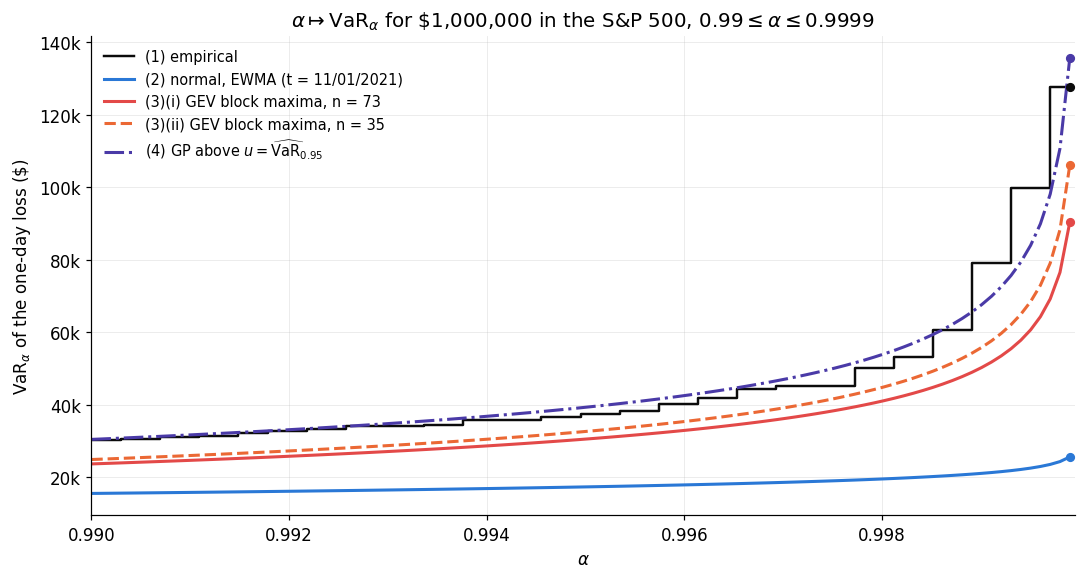

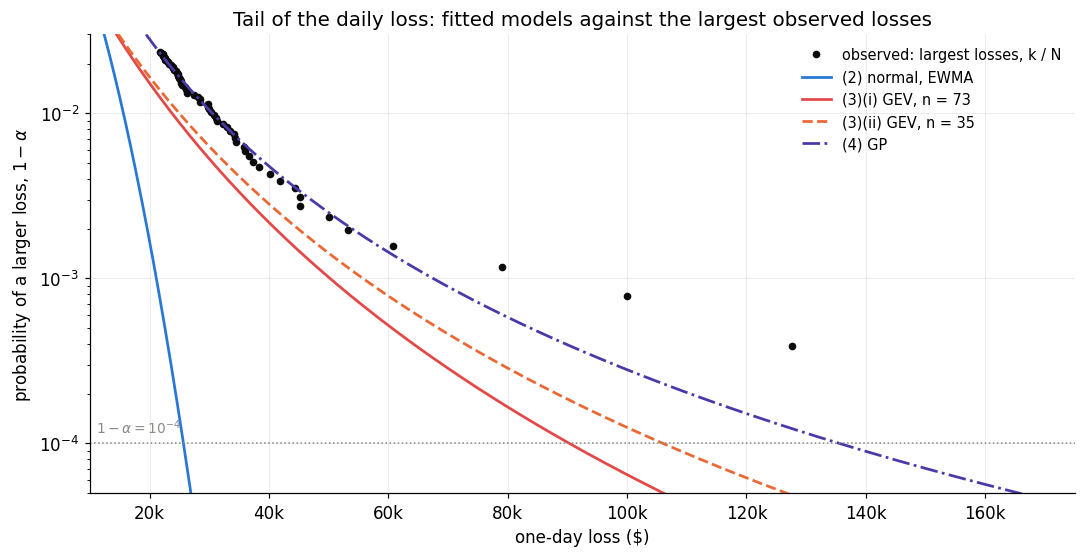

saved evt_var_curves.png and evt_tail_fit.png


In [12]:
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.step(ALPHAS, VAR_EMP, where="post", color=C_EMP, lw=1.6, label="(1) empirical")
ax.plot(ALPHAS, VAR_NORM, color=C_NORM, lw=2.0, label="(2) normal, EWMA (t = 11/01/2021)")
ax.plot(ALPHAS, VAR_GEV[73], color=C_GEV1, lw=2.0, label="(3)(i) GEV block maxima, n = 73")
ax.plot(ALPHAS, VAR_GEV[35], color=C_GEV2, lw=2.0, ls="--", label="(3)(ii) GEV block maxima, n = 35")
ax.plot(ALPHAS, VAR_GP, color=C_GP, lw=2.0, ls="-.", label=r"(4) GP above $u=\widehat{\mathrm{VaR}}_{0.95}$")
for v, col in ((VAR_EMP[-1], C_EMP), (VAR_NORM[-1], C_NORM), (VAR_GEV[73][-1], C_GEV1),
               (VAR_GEV[35][-1], C_GEV2), (VAR_GP[-1], C_GP)):
    ax.plot(A_TOP, v, "o", color=col, ms=5, zorder=5)
ax.set_xlabel(r"$\alpha$"); ax.set_ylabel(r"VaR$_\alpha$ of the one-day loss (\$)")
ax.set_xlim(0.99, 0.99995)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_title(r"$\alpha\mapsto$VaR$_\alpha$ for \$1,000,000 in the S&P 500, $0.99\leq\alpha\leq0.9999$")
ax.legend(loc="upper left", fontsize=9.5)
fig.tight_layout(); fig.savefig(FIG1, bbox_inches="tight"); plt.show()

# tail plot: probability of exceeding a loss level, log scale, with the observed losses
fig, ax = plt.subplots(figsize=(10, 5.2))
k = np.arange(1, 61)
emp_x = LOSS_SORTED[::-1][:60]                    # 60 largest losses
ax.plot(emp_x, k / N, "o", color=C_EMP, ms=4, label="observed: largest losses, k / N")
grid_a = 1 - np.logspace(np.log10(0.03), -5, 300)
ax.plot(-V_PORT * MU_T + V_PORT * SD_T * norm.ppf(grid_a), 1 - grid_a, color=C_NORM, lw=1.8, label="(2) normal, EWMA")
ax.plot(var_gev(grid_a, 73), 1 - grid_a, color=C_GEV1, lw=1.8, label="(3)(i) GEV, n = 73")
ax.plot(var_gev(grid_a, 35), 1 - grid_a, color=C_GEV2, lw=1.8, ls="--", label="(3)(ii) GEV, n = 35")
ga = grid_a[grid_a >= F_U]
ax.plot(var_gp(ga), 1 - ga, color=C_GP, lw=1.8, ls="-.", label="(4) GP")
ax.axhline(1 - A_TOP, color=C_MUTE, lw=1, ls=":")
ax.text(11_000, (1 - A_TOP) * 1.15, r"$1-\alpha=10^{-4}$", color=C_MUTE, fontsize=9)
ax.set_yscale("log"); ax.set_ylim(5e-5, 0.03); ax.set_xlim(10_000, 175_000)
ax.set_xlabel("one-day loss (\\$)"); ax.set_ylabel(r"probability of a larger loss, $1-\alpha$")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_title("Tail of the daily loss: fitted models against the largest observed losses")
ax.legend(loc="upper right", fontsize=9.5)
fig.tight_layout(); fig.savefig(FIG2, bbox_inches="tight"); plt.show()
print(f"saved {FIG1} and {FIG2}")

---
## 12. All numbers for the written PDF

In [13]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"[DATA]   N+1 = {len(prices)} closes {prices.index[0].date()} -> {LAST_DAY}; N = {N}; max loss {LOSS.max():,.4f} "
      f"on {logret.index[LOSS.argmax()].date()}")
print(f"[(1)]    VaR_0.95 = u = {U:,.4f} (l_{int(np.ceil(N * 0.95))});  VaR_0.99 = {var_empirical(0.99):,.4f};"
      f"  VaR_0.9999 = {VAR_EMP[-1]:,.4f}")
print(f"[(2)]    t = {T_EWMA}: mu = {MU_T:.8f}, sigma = {SD_T:.8f};  VaR_0.99 = {VAR_NORM[0]:,.4f};  VaR_0.9999 = {VAR_NORM[-1]:,.4f}")
for n, _ in BLOCKS:
    g = GEV[n]
    print(f"[(3) n={n}] xi = {g['xi']:.6f}, mu = {g['mu']:,.4f}, sigma = {g['sigma']:,.4f};  "
          f"VaR_0.99 = {VAR_GEV[n][0]:,.4f};  VaR_0.9999 = {VAR_GEV[n][-1]:,.4f}")
print(f"[(4)]    N_u = {len(EXC)}, xi = {XI_GP:.6f}, beta = {BETA_GP:,.4f};  VaR_0.99 = {VAR_GP[0]:,.4f};  VaR_0.9999 = {VAR_GP[-1]:,.4f}")

SUMMARY OF RESULTS
[DATA]   N+1 = 2556 closes 2011-11-01 -> 2021-12-28; N = 2555; max loss 127,652.1976 on 2020-03-16
[(1)]    VaR_0.95 = u = 15,252.8608 (l_2428);  VaR_0.99 = 30,230.1823;  VaR_0.9999 = 127,652.1976
[(2)]    t = 2021-11-01: mu = 0.00121010, sigma = 0.00722707;  VaR_0.99 = 15,602.5844;  VaR_0.9999 = 25,667.4986
[(3) n=73] xi = 0.181496, mu = 20,958.1755, sigma = 8,732.7176;  VaR_0.99 = 23,740.0577;  VaR_0.9999 = 90,353.4020
[(3) n=35] xi = 0.214112, mu = 15,298.8293, sigma = 8,246.1542;  VaR_0.99 = 24,954.1592;  VaR_0.9999 = 106,041.4500
[(4)]    N_u = 127, xi = 0.265563, beta = 7,594.2661;  VaR_0.99 = 30,502.8987;  VaR_0.9999 = 135,614.3056


---
## 13. Self-checks

In [14]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("N + 1 = 2556 closes, N = 2555 returns", len(prices) == 2556 and N == 2555)
check("alpha grid: 101 points from 0.99 to 0.9999 in steps of 0.000099",
      len(ALPHAS) == 101 and np.allclose(np.diff(ALPHAS), 0.000099))
check("empirical VaR uses l_(ceil(N alpha)); VaR_0.9999 is the sample maximum",
      var_empirical(0.99) == LOSS_SORTED[int(np.ceil(N * 0.99)) - 1] and VAR_EMP[-1] == LOSS.max())
mu_c, s2_c = X[:N_INIT].mean(), X[:N_INIT].var(ddof=1)
for xs in X[N_INIT:i_t + 1]:
    mu_c, s2_c = LAM * mu_c + (1 - LAM) * xs, THETA * s2_c + (1 - THETA) * (xs - mu_c) ** 2
check("EWMA re-computed in a second loop (variance with the old mean)", np.isclose(mu_c, MU_T) and np.isclose(s2_c, S2_T))
check("normal VaR formula matches scipy's normal quantile",
      np.allclose(VAR_NORM, norm.ppf(ALPHAS, loc=-V_PORT * MU_T, scale=V_PORT * SD_T)))
for n, m in BLOCKS:
    g = GEV[n]
    check(f"GEV n={n}: {m} blocks of {n} days cover all {N} returns", n * m == N and len(g["maxima"]) == m)
    check(f"GEV n={n}: closed-form VaR = scipy ppf at alpha^n",
          np.allclose(VAR_GEV[n], V_PORT * genextreme.ppf(ALPHAS ** n, g["c"], g["mu"] / V_PORT, g["sigma"] / V_PORT)))
    check(f"GEV n={n}: fitted model reproduces P(max <= VaR) = alpha^n",
          np.isclose(genextreme.cdf(VAR_GEV[n][-1] / V_PORT, g["c"], g["mu"] / V_PORT, g["sigma"] / V_PORT), A_TOP ** n))
    check(f"GEV n={n}: polishing did not lower the likelihood", g["nll"] <= g["nll0"] + 1e-9)
    # the fit is a local optimum: small moves of each parameter do not improve the likelihood
    base = np.array([g["c"], g["mu"] / V_PORT, g["sigma"] / V_PORT])
    worse = all(genextreme.nnlf(base + s * h * np.eye(3)[i], g["maxima"]) >= g["nll"] - 1e-9
                for i, h in enumerate((1e-3, 1e-6, 1e-6)) for s in (-1, 1))
    check(f"GEV n={n}: likelihood is at a local maximum", worse)
check("GP: excesses are positive and fitted with location 0", (EXC > 0).all())
check("GP: closed-form VaR at alpha = 0.95 equals u", np.isclose(var_gp(F_U), U))
check("GP: model tail probability at VaR equals 1 - alpha",
      np.isclose((1 - F_U) * genpareto.sf((VAR_GP[-1] - U) / V_PORT, XI_GP, 0, BETA_GP / V_PORT), 1 - A_TOP))
check("GP: polishing did not lower the likelihood", NLL_GP <= NLL_GP0 + 1e-9)
check("all VaR curves are increasing in alpha",
      all(np.all(np.diff(v) >= 0) for v in (VAR_EMP, VAR_NORM, VAR_GEV[73], VAR_GEV[35], VAR_GP)))
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  N + 1 = 2556 closes, N = 2555 returns
  [PASS]  alpha grid: 101 points from 0.99 to 0.9999 in steps of 0.000099
  [PASS]  empirical VaR uses l_(ceil(N alpha)); VaR_0.9999 is the sample maximum
  [PASS]  EWMA re-computed in a second loop (variance with the old mean)
  [PASS]  normal VaR formula matches scipy's normal quantile
  [PASS]  GEV n=73: 35 blocks of 73 days cover all 2555 returns
  [PASS]  GEV n=73: closed-form VaR = scipy ppf at alpha^n
  [PASS]  GEV n=73: fitted model reproduces P(max <= VaR) = alpha^n
  [PASS]  GEV n=73: polishing did not lower the likelihood
  [PASS]  GEV n=73: likelihood is at a local maximum
  [PASS]  GEV n=35: 73 blocks of 35 days cover all 2555 returns
  [PASS]  GEV n=35: closed-form VaR = scipy ppf at alpha^n
  [PASS]  GEV n=35: fitted model reproduces P(max <= VaR) = alpha^n
  [PASS]  GEV n=35: polishing did not lower the likelihood
  [PASS]  GEV n=35: likelihood is at a local maximum
  [PASS]  GP: excesses are positive and fitted with locat